# 10 | Joint tractography and FC sampling uncertainty

**Learning goals:** resample the 20-run SC estimator; preserve edge dependence; distinguish fixed support from selecting it again; cross SC with temporal and fully refitted matched FC; interpret conditional ranges without making a surgical claim.

**Primary FC stability:** notebook 14 recommends 97 distinct frames per session from nonreplacement ten-frame blocks, with complete WM/CSF nuisance refitting. These equal-duration subset ranges are conditional stability summaries, not full-run confidence intervals. The observed full-run points remain unchanged. Notebooks 10/11/13 retain earlier bootstrap, matching and mechanism analyses as sensitivities. See `config/PRIMARY_FC_RESAMPLING.md`. **Current SC policy:** graphs, network means and simulations use each session's 16/20 consensus with mean counts per 10,000 attempted seeds. Primary paired coupling uses the 823-edge intersection with session-specific weights. See `config/PRIMARY_SC.md`. Historical seed-160 diagnostics in notebooks 07/08 remain sensitivity analyses; notebook 09 supplies the reliability evidence. Notebook 10 quantifies joint seed/FC sampling under this policy, including matched designs and support reselection. Notebook 11 extends the full-run branch to paired nuisance refits; notebook 12 integrates all clinical/context fields with network uncertainty. Notebook 13 diagnoses PCA-training shifts and compares nonreplacement blocks at matched distinct counts and 80% retention. The rule is post hoc and does not validate anatomy or a surgical/cognitive effect.

In [1]:
from pathlib import Path
import os, sys, json
root = Path.cwd() if (Path.cwd()/"pyproject.toml").exists() else Path.cwd().parent
os.environ.setdefault("MPLCONFIGDIR", str(root/".cache/matplotlib"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, Markdown, Image
from pat16 import ROOT, DATA, RESULTS, SESSIONS
from pat16.connectivity import labels
from pat16.primary_sc import load_weights
nodes = pd.read_csv(RESULTS/"nodes.csv")
summary = json.loads((RESULTS/"summary.json").read_text())
plt.rcParams.update({"figure.figsize": (9,4), "font.size": 10})


## What is being resampled?
The recommended primary statistic is Spearman SC–FC coupling on the **823 common consensus edges**, with separate pre/post all-run mean SC weights per 10,000 seeds and anatomical-five-PC FC. Observed post−pre Δ is −0.04173 at primary FD and −0.03424 at strict FD. These point estimates stay unchanged.

We independently bootstrap **20 whole tractography runs with replacement** within each session, 500 times. This resamples the *20-run mean*, including zero counts, rather than substituting one tractogram. All edges in a run move together. For each of 200 paired FC draws, all cortical ROI signals use the same frame indices. We cross all SC and FC draws: 100,000 **dependent** cells per protocol, not 100,000 scans or independent subjects.

**Fixed support** locks the observed 823 connections and varies their mean weights. **Reselected support** reapplies detection ≥16/20 independently in both sessions and uses their intersection, reranking SC and FC each time. This includes support-selection sensitivity but changes the ranked edge population; it is not the identical fixed-population estimand. The 80% rule and all other primary choices remain fixed, not optimized by sign.

version                   joint-run-bootstrap-matched-fc-v1
SC_draws                                                500
FC_draws                                                200
cells_per_crossed_grid                               100000
independent_grid_cells                                False
dtype: object

,session,support,observed_rho,median,q025,q975
86,preop,fixed,0.188216,0.175568,0.141150,0.209849
89,postop,fixed,0.146488,0.134320,0.102207,0.172380
92,preop,reselected,0.188216,0.177234,0.137217,0.215666
95,postop,reselected,0.146488,0.133400,0.097354,0.174061


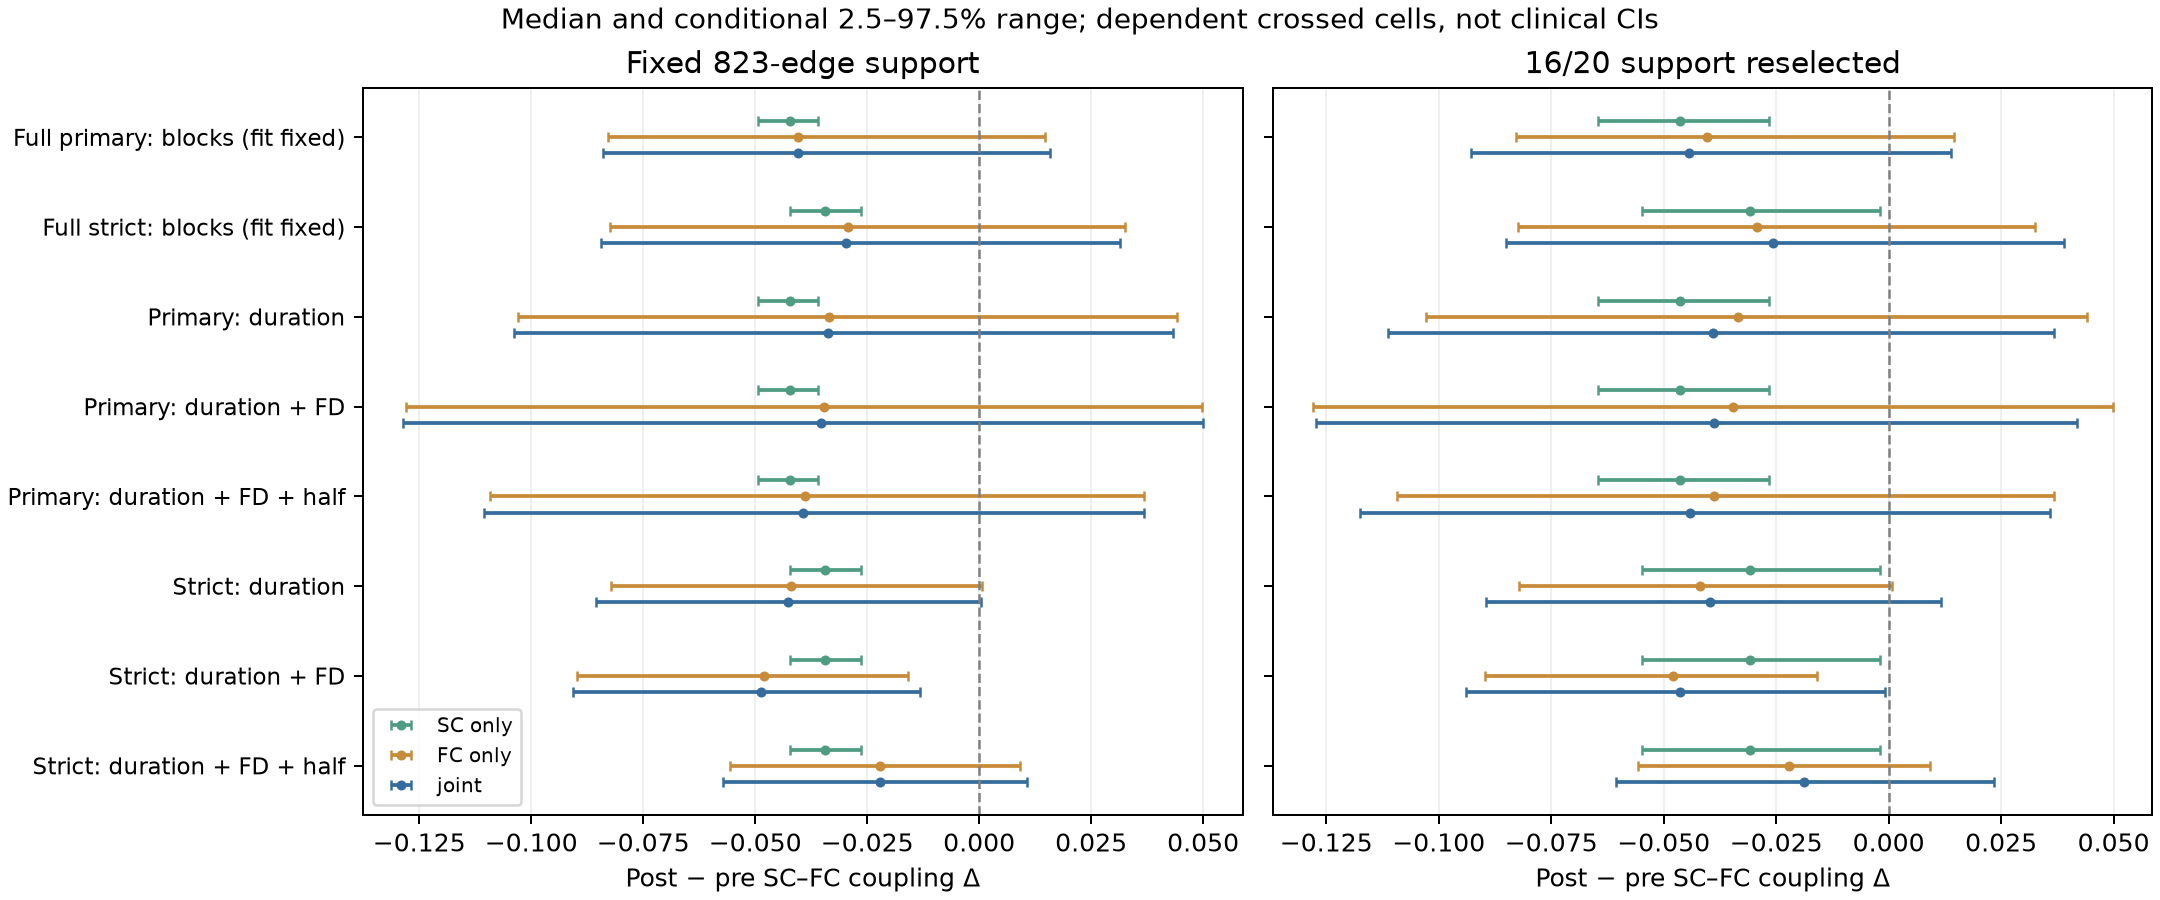

In [2]:
from pat16.joint_sampling import OUT as JOINT, I as ji, J as jj
joint_design=json.loads((JOINT/"design.json").read_text())
joint_summary=pd.read_csv(JOINT/"summary.csv")
support_qc=pd.read_csv(JOINT/"support_qc.csv")
fc_qc=pd.read_csv(JOINT/"fc_qc.csv")
display(pd.Series({k:joint_design[k] for k in ["version","SC_draws","FC_draws","cells_per_crossed_grid","independent_grid_cells"]}))
session_coupling=pd.read_csv(JOINT/"session_coupling.csv")
display(session_coupling[(session_coupling.protocol=="primary_block10")&(session_coupling.source=="joint")][["session","support","observed_rho","median","q025","q975"]])
display(Image(filename=str(RESULTS/"figures/joint_sampling_ranges.png")))

## Historical frozen full-run branch; see notebook 11 for refits
Temporal sampling and nuisance training are different
Full-run temporal resampling draws circular blocks of **10 original frames (24 s)**, omits censored members *within each block*, and continues until the original retained count is reached (146/150 primary, 68/96 strict). We never concatenate good frames before drawing blocks. All 100 ROI residuals move together. The session's censor-specific nuisance model is **frozen**: these ranges condition on its training. Blocks of 5/20 frames (12/48 s) test this arbitrary temporal scale. Repeated indices reduce distinct observations; the original regression df must not be assigned to them. Circular stationarity and within-run representativeness are assumptions.

The six **matched protocols** use the saved 68-distinct-frame masks: duration, duration+FD and duration+FD+run-half in primary/strict eligible pools. Tissue temporal projection, scaling, five PCs and regression are **fully refitted** on every subset, on the original 180-frame basis. These are subsampling designs without replacement, not block-bootstrap CIs. FD pairs use the existing 0.015-mm caliper. Strict pre-op has exactly 68 eligible frames: **its matched FC is constant**, and matched FC variability is postoperative only.

Matched sampling and full-run block sampling answer different questions. Neither provides scan–rescan error or a calibrated interval for a surgical effect. See `config/JOINT_SAMPLING.md`; circular blocks are motivated by temporal dependence (Bellec et al., 2008, report bibliography), whose test calibration is not asserted for this censored rank statistic.

,source,observed_delta,median,q025,q975,sd,positive_fraction
42,SC_only,-0.041728,-0.042174,-0.049343,-0.035964,0.003458,0.00000
43,FC_only,-0.041728,-0.040400,-0.082935,0.014614,0.026383,0.10000
44,joint,-0.041728,-0.040499,-0.083903,0.015845,0.026506,0.09162


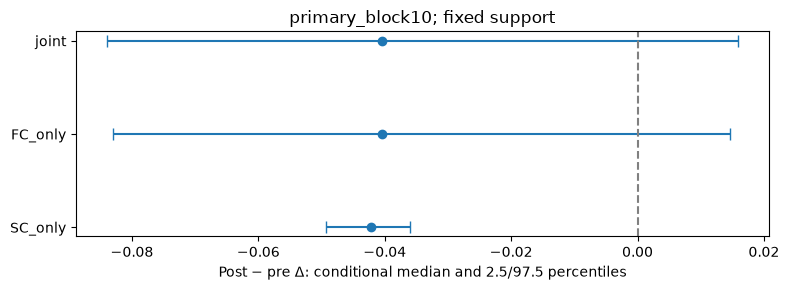

interactive(children=(Dropdown(description='protocol', index=7, options=('primary_duration', 'primary_motion',…

<function __main__.joint_ranges(protocol='primary_block10', support='fixed')>

In [3]:
def joint_ranges(protocol="primary_block10",support="fixed"):
    v=joint_summary[(joint_summary.protocol==protocol)&(joint_summary.support==support)]
    display(v[["source","observed_delta","median","q025","q975","sd","positive_fraction"]])
    fig,ax=plt.subplots(figsize=(8,3));y=np.arange(len(v))
    ax.errorbar(v["median"],y,xerr=np.vstack([v["median"]-v.q025,v.q975-v["median"]]),fmt="o",capsize=4)
    ax.axvline(0,color="gray",ls="--");ax.set_yticks(y,v.source)
    ax.set_xlabel("Post − pre Δ: conditional median and 2.5/97.5 percentiles")
    ax.set_title(protocol+"; "+support+" support");plt.tight_layout();plt.show();plt.close(fig)
widgets.interact(joint_ranges,protocol=widgets.Dropdown(options=joint_design["protocols"],value="primary_block10"),support=widgets.Dropdown(options=["fixed","reselected"]))

## Inspect an actual crossed cell
SC and FC draws are independent computational axes; pre/post run numbers are never assumed to correspond. Each saved grid stores both session correlations and Δ. FC-only holds the point SC/support fixed. SC-only holds the *observed full-run FC* fixed, even for a matched protocol: it is an observed-data anchor, not the SC main effect after averaging over matched FC. The joint grid evaluates both perturbations together and reranks on the actual support. Percentiles of marginal sources cannot be added.

Positive fractions are empirical sensitivity summaries. The reused rows/columns make binomial error bars based on 100,000 cells invalid, and a fraction is not a probability of neural improvement.

preop_rho       0.149223
postop_rho      0.100353
delta          -0.048870
SC_draw         0.000000
FC_draw         0.000000
edges         823.000000
dtype: float64

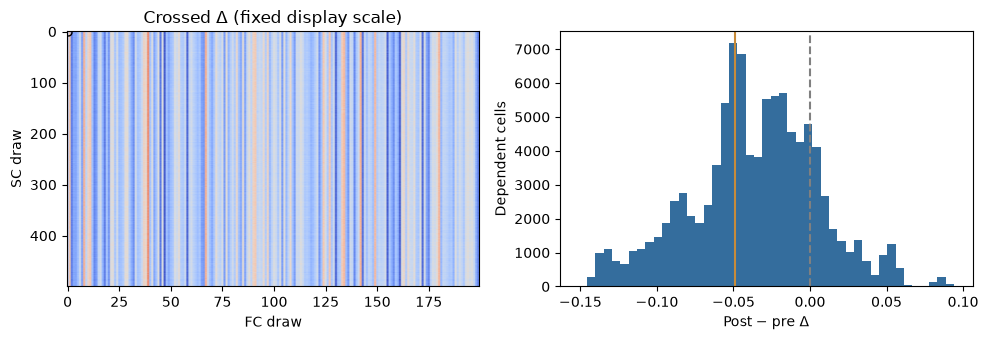

,protocol,session,draw,retained,unique_frames,design_rank,residual_df,mean_fd,nuisance
400,primary_motion,preop,0,68,68,39.0,29.0,0.263990,fully_refit
600,primary_motion,postop,0,68,68,39.0,29.0,0.261599,fully_refit


interactive(children=(Dropdown(description='protocol', index=1, options=('primary_duration', 'primary_motion',…

<function __main__.crossed_cell(protocol='primary_motion', support='fixed', sc_draw=0, fc_draw=0)>

In [4]:
fc_vectors=np.load(JOINT/"fc_draws.npy",mmap_mode="r")
sc_vectors=np.load(JOINT/"sc_weights.npy",mmap_mode="r")
selected_support=np.load(JOINT/"sc_selected_support.npy",mmap_mode="r")
fixed_support=np.load(RESULTS/"primary_sc/preop/common_support.npy")[ji,jj]
def crossed_cell(protocol="primary_motion",support="fixed",sc_draw=0,fc_draw=0):
    with np.load(JOINT/f"{protocol}_{support}.npz") as z:
        delta=z["delta"];r=z["rho"][:,sc_draw,fc_draw]
        display(pd.Series({"preop_rho":r[0],"postop_rho":r[1],"delta":r[1]-r[0],"SC_draw":sc_draw,"FC_draw":fc_draw,"edges":int(fixed_support.sum() if support=="fixed" else selected_support[sc_draw].sum())}))
        fig,axs=plt.subplots(1,2,figsize=(10,3.5))
        axs[0].imshow(delta,aspect="auto",cmap="coolwarm",vmin=-.15,vmax=.15)
        axs[0].plot(fc_draw,sc_draw,"o",ms=5,mfc="none",mec="black")
        axs[0].set(xlabel="FC draw",ylabel="SC draw",title="Crossed Δ (fixed display scale)")
        axs[1].hist(delta.ravel(),bins=45,color="#346d9d");axs[1].axvline(0,color="gray",ls="--")
        axs[1].axvline(r[1]-r[0],color="#c88b39");axs[1].set(xlabel="Post − pre Δ",ylabel="Dependent cells")
        plt.tight_layout();plt.show();plt.close(fig)
    display(fc_qc[(fc_qc.protocol==protocol)&(fc_qc.draw==fc_draw)])
widgets.interact(crossed_cell,protocol=widgets.Dropdown(options=joint_design["protocols"],value="primary_motion"),support=widgets.Dropdown(options=["fixed","reselected"]),sc_draw=widgets.IntSlider(min=0,max=499,value=0),fc_draw=widgets.IntSlider(min=0,max=199,value=0))

## Where does the conditional grid variance come from?
For Δ(b,f), subtract its grand mean. The SC main effect is the centered mean of each row, the FC main effect is the centered mean of each column, and interaction is what remains. With equal product weights these are orthogonal; their population variances sum **exactly** to the grid variance. This is a description of the chosen independent computational perturbations, not identification of independent biological errors.

Support re-selection changes both the connection population and the rank context. Its variance can be larger or smaller than fixed-support variance; ranges need not widen monotonically. Mean counts and consensus are selected from only 20 empirical seed runs, and repeatedly false pathways remain possible.

,protocol,support,SC_share,FC_share,interaction_share,total_variance
2,primary_duration,fixed,0.004586,0.991501,0.003913,0.001553
5,primary_duration,reselected,0.034077,0.902098,0.063825,0.001571
8,primary_motion,fixed,0.003984,0.992532,0.003485,0.001749
11,primary_motion,reselected,0.031255,0.911355,0.057389,0.001746
14,primary_motion_time,fixed,0.004871,0.991287,0.003842,0.001553
17,primary_motion_time,reselected,0.037003,0.900145,0.062853,0.001569
20,strict_duration,fixed,0.031290,0.964691,0.004019,0.000496
23,strict_duration,reselected,0.246424,0.701707,0.051868,0.000664
26,strict_motion,fixed,0.041016,0.953931,0.005053,0.000374
29,strict_motion,reselected,0.318121,0.625597,0.056281,0.000555


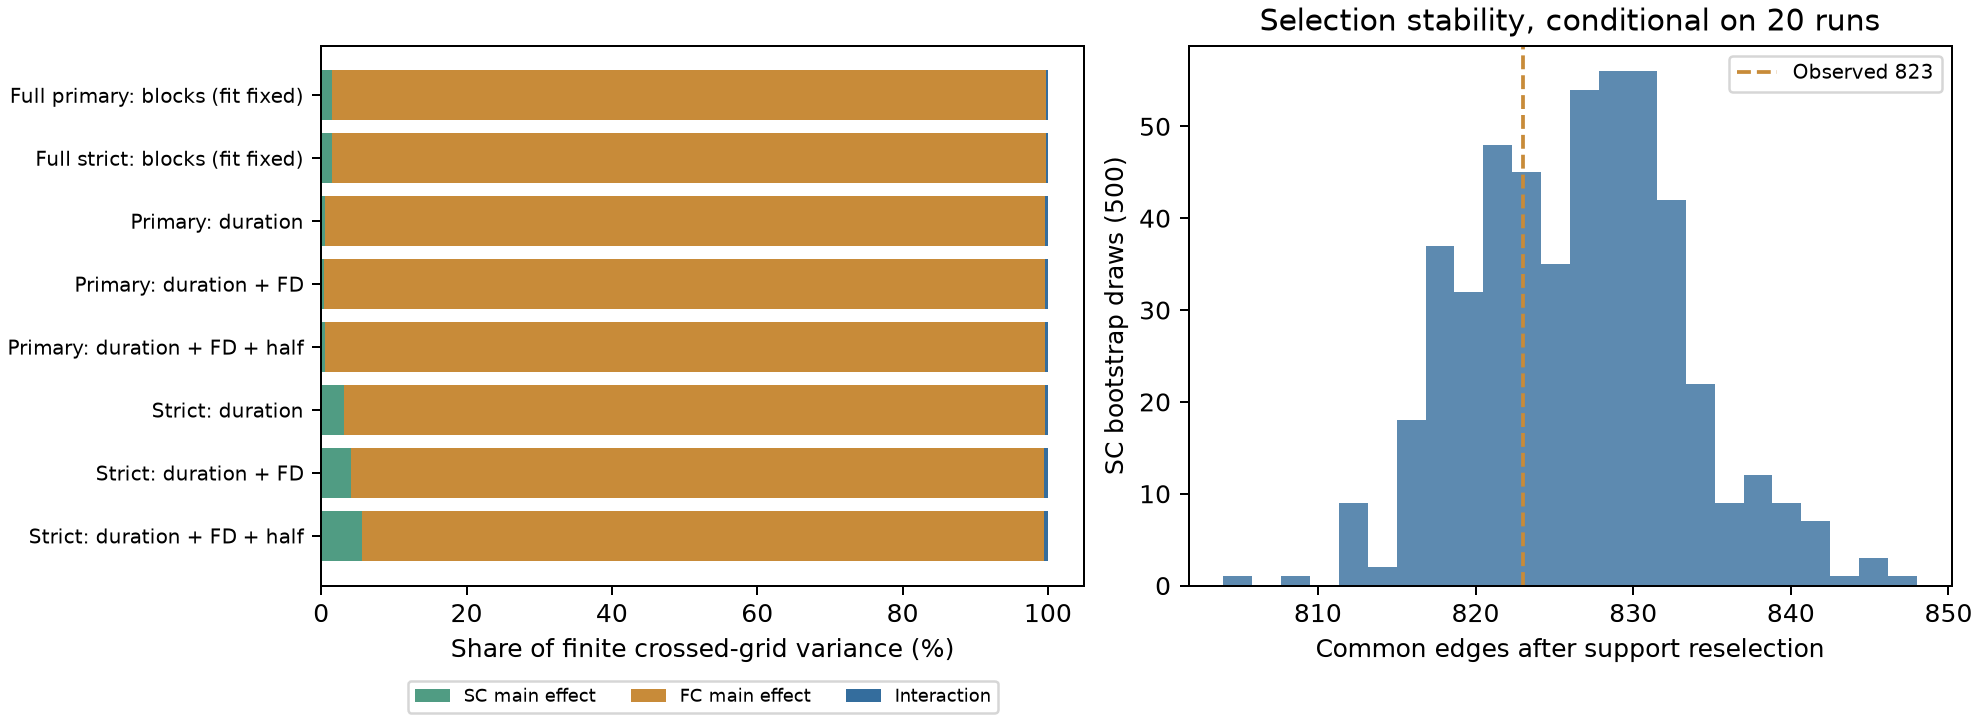

,common_edges,added_edges,removed_edges,jaccard
count,500.000000,500.000000,500.000000,500.000000
mean,826.370000,36.570000,33.200000,0.918906
std,6.727527,6.567752,5.742644,0.011501
min,804.000000,18.000000,18.000000,0.884439
2.5%,814.475000,24.475000,23.000000,0.896963
50%,826.000000,36.000000,33.000000,0.918841
97.5%,840.000000,50.000000,45.000000,0.940572
max,848.000000,58.000000,54.000000,0.951249


,node_i,node_j,point_common,bootstrap_common_frequency
4037,57,91,True,0.412
4659,76,86,True,0.414
4416,67,95,True,0.510
581,7,10,True,0.520
4895,90,91,True,0.532
1236,14,42,True,0.536
137,2,41,True,0.538
2185,26,37,True,0.548
1632,19,23,True,0.562
2040,24,41,True,0.562


In [5]:
joint_components=joint_summary[joint_summary.source=="joint"]
display(joint_components[["protocol","support","SC_share","FC_share","interaction_share","total_variance"]])
display(Image(filename=str(RESULTS/"figures/joint_sampling_components.png")))
display(support_qc[["common_edges","added_edges","removed_edges","jaccard"]].describe(percentiles=[.025,.5,.975]))
selection=pd.read_csv(JOINT/"edge_selection.csv")
display(selection[selection.point_common].sort_values("bootstrap_common_frequency").head(15))

## Temporal scale, finite Monte Carlo sampling and matching checks
Block length is not fitted to this case. Compare 5/10/20 frames under both censor pools; inspect matched protocols separately. Half-ensemble ranges reveal finite simulation sensitivity, especially in the tails. In the reselected strict FD-only design, the upper endpoint crosses zero in one FC half and remains negative in the other, so its small full-ensemble negative endpoint is not a stable directional result. The exact values are in the table below. They are not independent validation or a convergence proof. The six saved matching protocols and their motion/temporal QC remain in notebook 07. Every matched frame count is 68, regression rank 39, residual df 29; block draws have no newly fitted nuisance rank or df.

In [6]:
blocks=joint_summary[(joint_summary.source=="joint")&joint_summary.protocol.str.contains("block")]
display(blocks[["protocol","support","median","q025","q975","positive_fraction"]])
display(pd.read_csv(JOINT/"monte_carlo_halves.csv")[["protocol","support","half","median","q025","q975"]])
display(fc_qc.groupby(["protocol","session","nuisance"]).agg(retained=("retained","min"),unique_min=("unique_frames","min"),unique_median=("unique_frames","median"),unique_max=("unique_frames","max"),rank=("design_rank","first"),df=("residual_df","first")))

,protocol,support,median,q025,q975,positive_fraction
38,primary_block5,fixed,-0.041984,-0.079166,0.009583,0.04490
41,primary_block5,reselected,-0.045290,-0.086976,0.007386,0.04008
44,primary_block10,fixed,-0.040499,-0.083903,0.015845,0.09162
47,primary_block10,reselected,-0.044381,-0.092937,0.013765,0.06845
50,primary_block20,fixed,-0.040414,-0.083276,0.010647,0.05964
53,primary_block20,reselected,-0.043302,-0.090819,0.007901,0.04673
56,strict_block5,fixed,-0.032135,-0.086797,0.023294,0.12846
59,strict_block5,reselected,-0.026610,-0.089085,0.031350,0.19479
62,strict_block10,fixed,-0.029813,-0.084362,0.031463,0.17491
65,strict_block10,reselected,-0.025699,-0.085104,0.039046,0.21613


,protocol,support,half,median,q025,q975
0,primary_duration,fixed,SC_first,-0.033636,-0.103878,0.043436
1,primary_duration,fixed,SC_second,-0.033834,-0.104008,0.042962
2,primary_duration,fixed,FC_first,-0.035991,-0.098000,0.044963
3,primary_duration,fixed,FC_second,-0.032106,-0.105795,0.035959
4,primary_duration,reselected,SC_first,-0.038824,-0.110730,0.036599
...,...,...,...,...,...,...
91,strict_block20,fixed,FC_second,-0.034621,-0.088877,0.031689
92,strict_block20,reselected,SC_first,-0.028386,-0.094311,0.041874
93,strict_block20,reselected,SC_second,-0.029109,-0.095841,0.042577
94,strict_block20,reselected,FC_first,-0.027925,-0.100529,0.038651


retained  unique_min  unique_median  \
protocol            session nuisance                                           
primary_block10     postop  frozen_fit        150          74           96.0   
                    preop   frozen_fit        146          73           93.5   
primary_block20     postop  frozen_fit        150          66           99.0   
                    preop   frozen_fit        146          62           96.0   
primary_block5      postop  frozen_fit        150          75           96.0   
                    preop   frozen_fit        146          72           93.0   
primary_duration    postop  fully_refit        68          68           68.0   
                    preop   fully_refit        68          68           68.0   
primary_motion      postop  fully_refit        68          68           68.0   
                    preop   fully_refit        68          68           68.0   
primary_motion_time postop  fully_refit        68          68           68.0   
                    preop   fully_refit        68          68           68.0   
strict_block10      postop  frozen_fit         96          40           61.0   
                    preop   frozen_fit         68          29           44.5   
strict_block20      postop  frozen_fit         96          46           63.0   
                    preop   frozen_fit         68          27           45.0   
strict_block5       postop  frozen_fit         96          47           62.0   
                    preop   frozen_fit         68          32           44.0   
strict_duration     postop  fully_refit        68          68           68.0   
                    preop   fully_refit        68          68           68.0   
strict_motion       postop  fully_refit        68          68           68.0   
                    preop   fully_refit        68          68           68.0   
strict_motion_time  postop  fully_refit        68          68           68.0   
                    preop   fully_refit        68          68           68.0   

                                         unique_max  rank    df  
protocol            session nuisance                             
primary_block10     postop  frozen_fit          114   NaN   NaN  
                    preop   frozen_fit          120   NaN   NaN  
primary_block20     postop  frozen_fit          126   NaN   NaN  
                    preop   frozen_fit          127   NaN   NaN  
primary_block5      postop  frozen_fit          111   NaN   NaN  
                    preop   frozen_fit          107   NaN   NaN  
primary_duration    postop  fully_refit          68  39.0  29.0  
                    preop   fully_refit          68  39.0  29.0  
primary_motion      postop  fully_refit          68  39.0  29.0  
                    preop   fully_refit          68  39.0  29.0  
primary_motion_time postop  fully_refit          68  39.0  29.0  
                    preop   fully_refit          68  39.0  29.0  
strict_block10      postop  frozen_fit           75   NaN   NaN  
                    preop   frozen_fit           56   NaN   NaN  
strict_block20      postop  frozen_fit           85   NaN   NaN  
                    preop   frozen_fit           61   NaN   NaN  
strict_block5       postop  frozen_fit           72   NaN   NaN  
                    preop   frozen_fit           53   NaN   NaN  
strict_duration     postop  fully_refit          68  39.0  29.0  
                    preop   fully_refit          68  39.0  29.0  
strict_motion       postop  fully_refit          68  39.0  29.0  
                    preop   fully_refit          68  39.0  29.0  
strict_motion_time  postop  fully_refit          68  39.0  29.0  
                    preop   fully_refit          68  39.0  29.0

## Reproduce and interpret
Run `uv run python scripts/investigate_joint_sampling.py`, then `uv run python scripts/run_all.py --notebooks --report`. The new analysis is separate under `results/joint_sampling/`: all SC run indices, weights, supports, FC matrices, block indices, matched masks, QC and 24 crossed grids are saved. `design.json` fingerprints source/config/input/output files. The preceding delivery is preserved under `results/before_joint_sampling/`.

The point estimates and recommended policy are unchanged. Conditional seed and FC sampling must be assessed together, while the full-run branch still conditions on nuisance training and the matched branch still conditions on measured motion and short eligible pools. Acquisition, image noise, registration, tissue masks, model choice, vascular changes and repeated clinical assessments are not resampled. None of these ranges establishes a surgical, cognitive or quality-of-life effect.